# Value of Time (VoT) Sensitivity Analysis

This notebook analyzes how different Value of Time assumptions affect:
- Total system costs
- BEV adoption rates
- Technology transition timing
- Charging patterns

**Scenarios:**
- vot_10: EUR 10/hour
- vot_20: EUR 20/hour  
- vot_30: EUR 30/hour (baseline)
- vot_45: EUR 45/hour
- vot_60: EUR 60/hour

All scenarios use Go RES v1.2 (EUR 500/tCO2 in 2040), 500 trucks/year threshold, with mandatory breaks constraint.

In [120]:
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from collections import defaultdict

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('Libraries loaded')

Libraries loaded


In [121]:
# Configuration
BASE_DIR = os.getcwd()
RESULTS_DIR = os.path.join(BASE_DIR, 'results', 'vot_sensitivity_new')

# VoT scenarios
VOT_VALUES = [10, 20, 30, 45, 60]
SCENARIOS = [f'vot_{v}' for v in VOT_VALUES]

SCENARIO_LABELS = {f'vot_{v}': f'EUR {v}/h' for v in VOT_VALUES}
SCENARIO_COLORS = {
    'vot_10': '#2ecc71',  # green (low cost)
    'vot_20': '#3498db',  # blue
    'vot_30': '#9b59b6',  # purple (baseline)
    'vot_45': '#e67e22',  # orange
    'vot_60': '#e74c3c',  # red (high cost)
}

print(f'Results directory: {RESULTS_DIR}')
print(f'Scenarios: {SCENARIOS}')

Results directory: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\vot_sensitivity_new
Scenarios: ['vot_10', 'vot_20', 'vot_30', 'vot_45', 'vot_60']


In [122]:
# Helper functions
def get_latest_file(folder, suffix):
    """Get the most recent file matching the suffix pattern in the folder."""
    if not os.path.exists(folder):
        return None
    pattern = os.path.join(folder, f'*{suffix}')
    files = glob(pattern)
    if not files:
        return None
    return max(files, key=os.path.getmtime)

def extract_fleet_by_year(h_dict):
    """Extract fleet totals by year and technology from h_dict."""
    fleet = defaultdict(lambda: {'BEV': 0, 'ICEV': 0})
    
    for key_str, value in h_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            year = key[0]
            tv_id = key[1]  # techvehicle ID
            
            # Convert value to float if string
            val = float(value) if isinstance(value, str) else value
            
            # tv_id 1 = BEV, tv_id 0 = ICEV
            if tv_id == 1:
                fleet[year]['BEV'] += val
            else:
                fleet[year]['ICEV'] += val
        except Exception:
            continue
    
    return dict(fleet)

print('Helper functions defined')

Helper functions defined


In [123]:
# Load batch summary
summary_file = os.path.join(RESULTS_DIR, 'batch_summary.yaml')
with open(summary_file, 'r') as f:
    batch_summary = yaml.safe_load(f)

# Extract objective values (convert from string to float)
obj_values = {}
for scenario in SCENARIOS:
    if scenario in batch_summary:
        obj_val = batch_summary[scenario]['objective_value']
        obj_values[scenario] = float(obj_val) if isinstance(obj_val, str) else obj_val
        print(f'{SCENARIO_LABELS[scenario]}: {obj_values[scenario]:.2e} EUR')

# Create DataFrame
obj_df = pd.DataFrame([
    {'VoT': v, 'Scenario': f'vot_{v}', 'Objective': obj_values[f'vot_{v}']}
    for v in VOT_VALUES
])
obj_df['Objective_Billion'] = obj_df['Objective'] / 1e9
obj_df

EUR 10/h: 9.62e+10 EUR
EUR 20/h: 1.63e+11 EUR
EUR 30/h: 2.30e+11 EUR
EUR 45/h: 3.31e+11 EUR
EUR 60/h: 4.31e+11 EUR


,VoT,Scenario,Objective,Objective_Billion
0,10,vot_10,9.619335e+10,96.193346
1,20,vot_20,1.632598e+11,163.259775
2,30,vot_30,2.303139e+11,230.313914
3,45,vot_45,3.308844e+11,330.884430
4,60,vot_60,4.314457e+11,431.445653


## 1. Load Results and Objective Values

In [124]:
# Load batch summary
summary_file = os.path.join(RESULTS_DIR, 'batch_summary.yaml')
with open(summary_file, 'r') as f:
    batch_summary = yaml.safe_load(f)

# Extract objective values
obj_values = {}
for scenario in SCENARIOS:
    if scenario in batch_summary:
        obj_val = batch_summary[scenario]['objective_value']
        obj_values[scenario] = float(obj_val) if isinstance(obj_val, str) else obj_val
        print(f'{SCENARIO_LABELS[scenario]}: {obj_values[scenario]:.2e} EUR')

# Create DataFrame
obj_df = pd.DataFrame([
    {'VoT': v, 'Scenario': f'vot_{v}', 'Objective': obj_values[f'vot_{v}']}
    for v in VOT_VALUES
])
obj_df['Objective_Billion'] = obj_df['Objective'] / 1e9
obj_df

EUR 10/h: 9.62e+10 EUR
EUR 20/h: 1.63e+11 EUR
EUR 30/h: 2.30e+11 EUR
EUR 45/h: 3.31e+11 EUR
EUR 60/h: 4.31e+11 EUR


,VoT,Scenario,Objective,Objective_Billion
0,10,vot_10,9.619335e+10,96.193346
1,20,vot_20,1.632598e+11,163.259775
2,30,vot_30,2.303139e+11,230.313914
3,45,vot_45,3.308844e+11,330.884430
4,60,vot_60,4.314457e+11,431.445653


Saved: figures/vot_objective_values.pdf


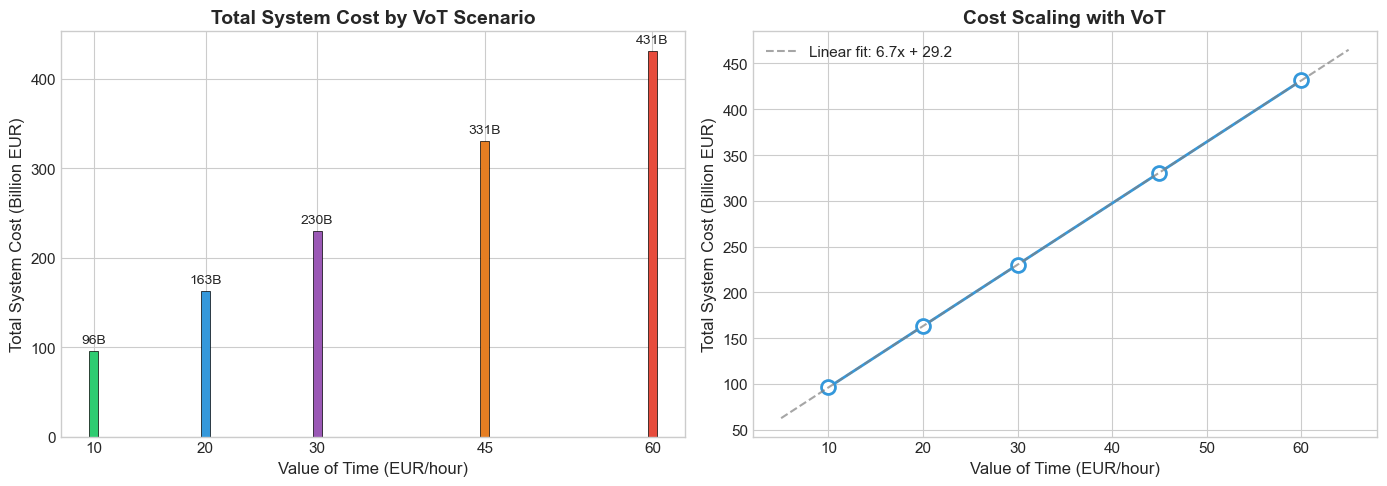

In [125]:
# Plot objective values vs VoT
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Bar chart
colors = [SCENARIO_COLORS[f'vot_{v}'] for v in VOT_VALUES]
bars = ax1.bar(obj_df['VoT'], obj_df['Objective_Billion'], color=colors, edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Value of Time (EUR/hour)', fontsize=12)
ax1.set_ylabel('Total System Cost (Billion EUR)', fontsize=12)
ax1.set_title('Total System Cost by VoT Scenario', fontsize=14, fontweight='bold')
ax1.set_xticks(VOT_VALUES)

# Add value labels
for bar, val in zip(bars, obj_df['Objective_Billion']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5, 
             f'{val:.0f}B', ha='center', va='bottom', fontsize=10)

# Right: Line chart showing linear relationship
ax2.plot(obj_df['VoT'], obj_df['Objective_Billion'], 'o-', color='#3498db', 
         linewidth=2, markersize=10, markerfacecolor='white', markeredgewidth=2)
ax2.set_xlabel('Value of Time (EUR/hour)', fontsize=12)
ax2.set_ylabel('Total System Cost (Billion EUR)', fontsize=12)
ax2.set_title('Cost Scaling with VoT', fontsize=14, fontweight='bold')

# Add trend line
z = np.polyfit(obj_df['VoT'], obj_df['Objective_Billion'], 1)
p = np.poly1d(z)
x_trend = np.linspace(5, 65, 100)
ax2.plot(x_trend, p(x_trend), '--', color='gray', alpha=0.7, label=f'Linear fit: {z[0]:.1f}x + {z[1]:.1f}')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/vot_objective_values.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/vot_objective_values.png', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_objective_values.pdf')
plt.show()

## 2. BEV Adoption by VoT Scenario

In [126]:
# Load fleet data for all scenarios
fleet_data = {}

for scenario in SCENARIOS:
    scenario_path = os.path.join(RESULTS_DIR, scenario)
    h_file = get_latest_file(scenario_path, '_h_dict.yaml')
    
    if h_file:
        with open(h_file, 'r') as f:
            h_dict = yaml.safe_load(f)
        fleet_data[scenario] = extract_fleet_by_year(h_dict)
        print(f'Loaded: {scenario}')
    else:
        print(f'NOT FOUND: {scenario}')

print(f'\nLoaded {len(fleet_data)} scenarios')

Loaded: vot_10
Loaded: vot_20
Loaded: vot_30
Loaded: vot_45
Loaded: vot_60

Loaded 5 scenarios


In [127]:
# Calculate BEV shares by year for each scenario
years = sorted(list(fleet_data[SCENARIOS[0]].keys()))

bev_shares = {}
for scenario in SCENARIOS:
    shares = []
    for year in years:
        bev = fleet_data[scenario][year]['BEV']
        icev = fleet_data[scenario][year]['ICEV']
        total = bev + icev
        share = bev / total * 100 if total > 0 else 0
        shares.append(share)
    bev_shares[scenario] = shares

# Create DataFrame
share_df = pd.DataFrame({'Year': years})
for scenario in SCENARIOS:
    share_df[SCENARIO_LABELS[scenario]] = bev_shares[scenario]

print('BEV Share (%) by Year and VoT:')
display(share_df.round(1))

BEV Share (%) by Year and VoT:


,Year,EUR 10/h,EUR 20/h,EUR 30/h,EUR 45/h,EUR 60/h
0,2020,0.0,0.0,0.0,0.0,0.0
1,2024,0.0,0.0,0.0,0.0,0.0
2,2028,0.0,0.0,0.0,0.0,0.0
3,2032,0.0,0.0,0.0,0.0,0.0
4,2036,0.0,0.0,0.0,0.0,0.0
5,2040,0.0,0.0,0.0,0.0,0.0
6,2044,0.0,0.0,0.0,0.0,0.0
7,2048,0.0,0.0,0.0,0.0,0.0
8,2052,0.0,0.0,0.0,0.0,0.0
9,2056,0.0,0.0,0.0,0.0,0.0


Saved: figures/vot_bev_adoption.pdf


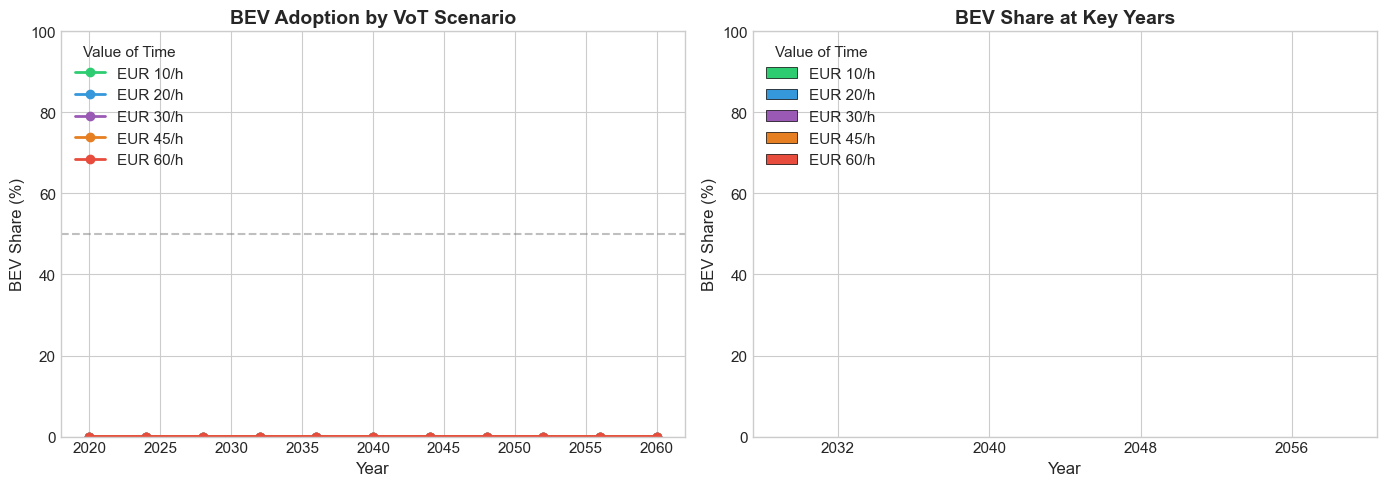

In [128]:
# Plot BEV adoption curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: BEV share over time
for scenario in SCENARIOS:
    ax1.plot(years, bev_shares[scenario], 'o-', 
             color=SCENARIO_COLORS[scenario], 
             label=SCENARIO_LABELS[scenario],
             linewidth=2, markersize=6)

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('BEV Share (%)', fontsize=12)
ax1.set_title('BEV Adoption by VoT Scenario', fontsize=14, fontweight='bold')
ax1.legend(title='Value of Time', loc='upper left')
ax1.set_ylim(0, 100)
ax1.axhline(y=50, color='gray', linestyle='--', alpha=0.5, label='50% threshold')

# Right: BEV share at key years by VoT
key_years = [2032, 2040, 2048, 2056]
x = np.arange(len(key_years))
width = 0.15

for i, scenario in enumerate(SCENARIOS):
    shares_at_years = [bev_shares[scenario][years.index(y)] for y in key_years]
    ax2.bar(x + i*width, shares_at_years, width, 
            label=SCENARIO_LABELS[scenario], 
            color=SCENARIO_COLORS[scenario],
            edgecolor='black', linewidth=0.5)

ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('BEV Share (%)', fontsize=12)
ax2.set_title('BEV Share at Key Years', fontsize=14, fontweight='bold')
ax2.set_xticks(x + width * 2)
ax2.set_xticklabels(key_years)
ax2.legend(title='Value of Time', loc='upper left')
ax2.set_ylim(0, 100)

plt.tight_layout()
plt.savefig('figures/vot_bev_adoption.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/vot_bev_adoption.png', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_bev_adoption.pdf')
plt.show()

Saved: figures/vot_bev_normalized_comparison.pdf


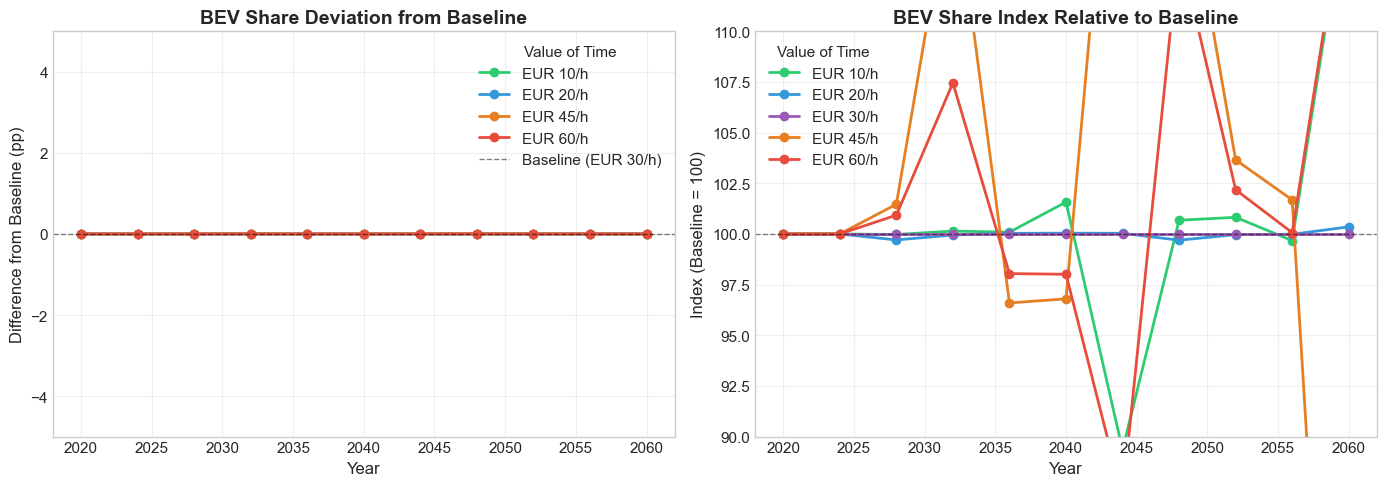

In [129]:
# Normalized comparison - BEV share relative to baseline (vot_30)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

baseline_scenario = 'vot_30'
baseline_shares = np.array(bev_shares[baseline_scenario])

# Left: Difference from baseline (percentage points)
for scenario in SCENARIOS:
    if scenario != baseline_scenario:
        diff = np.array(bev_shares[scenario]) - baseline_shares
        ax1.plot(years, diff, 'o-',
                 color=SCENARIO_COLORS[scenario],
                 label=SCENARIO_LABELS[scenario],
                 linewidth=2, markersize=6)

ax1.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Baseline (EUR 30/h)')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Difference from Baseline (pp)', fontsize=12)
ax1.set_title('BEV Share Deviation from Baseline', fontsize=14, fontweight='bold')
ax1.legend(title='Value of Time')
ax1.set_ylim(-5, 5)
ax1.grid(True, alpha=0.3)

# Right: Ratio to baseline (index, baseline = 100)
for scenario in SCENARIOS:
    # Avoid division by zero for early years
    ratio = []
    for i, year in enumerate(years):
        if baseline_shares[i] > 0:
            ratio.append(bev_shares[scenario][i] / baseline_shares[i] * 100)
        else:
            ratio.append(100)  # Both are 0, so ratio is 1
    
    ax2.plot(years, ratio, 'o-',
             color=SCENARIO_COLORS[scenario],
             label=SCENARIO_LABELS[scenario],
             linewidth=2, markersize=6)

ax2.axhline(y=100, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Index (Baseline = 100)', fontsize=12)
ax2.set_title('BEV Share Index Relative to Baseline', fontsize=14, fontweight='bold')
ax2.legend(title='Value of Time')
ax2.set_ylim(90, 110)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/vot_bev_normalized_comparison.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/vot_bev_normalized_comparison.png', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_bev_normalized_comparison.pdf')
plt.show()

In [130]:
# Analyze BEV share differences
print('BEV Share Analysis by VoT:')
print('=' * 70)

baseline_scenario = 'vot_30'
baseline_shares = bev_shares[baseline_scenario]

for year_idx, year in enumerate(years):
    if year in [2032, 2040, 2048, 2056]:
        print(f'\nYear {year}:')
        for scenario in SCENARIOS:
            share = bev_shares[scenario][year_idx]
            diff = share - baseline_shares[year_idx]
            diff_str = f'{diff:+.1f}pp' if scenario != baseline_scenario else '(baseline)'
            print(f'  {SCENARIO_LABELS[scenario]:>12}: {share:5.1f}%  {diff_str}')

BEV Share Analysis by VoT:

Year 2032:
      EUR 10/h:   0.0%  +0.0pp
      EUR 20/h:   0.0%  -0.0pp
      EUR 30/h:   0.0%  (baseline)
      EUR 45/h:   0.0%  +0.0pp
      EUR 60/h:   0.0%  +0.0pp

Year 2040:
      EUR 10/h:   0.0%  +0.0pp
      EUR 20/h:   0.0%  +0.0pp
      EUR 30/h:   0.0%  (baseline)
      EUR 45/h:   0.0%  -0.0pp
      EUR 60/h:   0.0%  -0.0pp

Year 2048:
      EUR 10/h:   0.0%  +0.0pp
      EUR 20/h:   0.0%  -0.0pp
      EUR 30/h:   0.0%  (baseline)
      EUR 45/h:   0.0%  +0.0pp
      EUR 60/h:   0.0%  +0.0pp

Year 2056:
      EUR 10/h:   0.0%  -0.0pp
      EUR 20/h:   0.0%  -0.0pp
      EUR 30/h:   0.0%  (baseline)
      EUR 45/h:   0.0%  +0.0pp
      EUR 60/h:   0.0%  +0.0pp


## 3. Fleet Size Comparison

Saved: figures/vot_bev_fleet_absolute.pdf


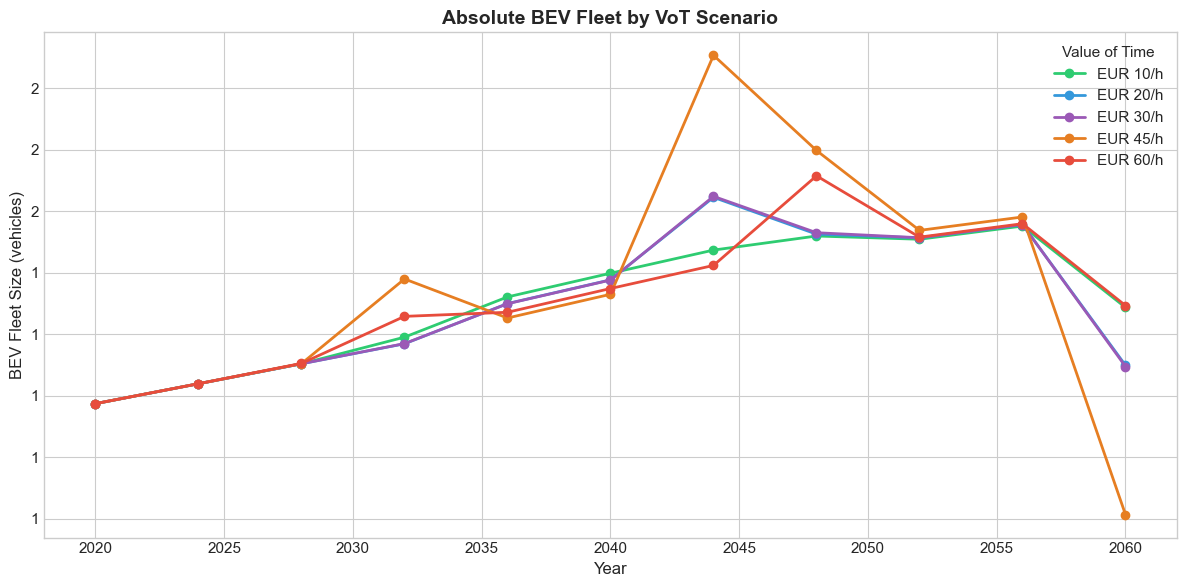

In [131]:
# Calculate absolute fleet sizes
fleet_sizes = {}
for scenario in SCENARIOS:
    fleet_sizes[scenario] = {
        'BEV': [fleet_data[scenario][y]['BEV'] for y in years],
        'ICEV': [fleet_data[scenario][y]['ICEV'] for y in years],
        'Total': [fleet_data[scenario][y]['BEV'] + fleet_data[scenario][y]['ICEV'] for y in years]
    }

# Plot absolute BEV fleet
fig, ax = plt.subplots(figsize=(12, 6))

for scenario in SCENARIOS:
    ax.plot(years, fleet_sizes[scenario]['BEV'], 'o-',
            color=SCENARIO_COLORS[scenario],
            label=SCENARIO_LABELS[scenario],
            linewidth=2, markersize=6)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('BEV Fleet Size (vehicles)', fontsize=12)
ax.set_title('Absolute BEV Fleet by VoT Scenario', fontsize=14, fontweight='bold')
ax.legend(title='Value of Time')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('figures/vot_bev_fleet_absolute.pdf', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_bev_fleet_absolute.pdf')
plt.show()

## 4. VoT Impact on Electrification Speed

In [132]:
# Find year when each scenario reaches certain BEV thresholds
thresholds = [25, 50, 75]

threshold_years = {}
for scenario in SCENARIOS:
    threshold_years[scenario] = {}
    for thresh in thresholds:
        for year_idx, year in enumerate(years):
            if bev_shares[scenario][year_idx] >= thresh:
                threshold_years[scenario][thresh] = year
                break
        else:
            threshold_years[scenario][thresh] = None

# Create summary table
print('Year Reaching BEV Threshold by VoT:')
print('=' * 60)
print(f'{"VoT":>12} | {"25% BEV":>10} | {"50% BEV":>10} | {"75% BEV":>10}')
print('-' * 60)

for scenario in SCENARIOS:
    row = f'{SCENARIO_LABELS[scenario]:>12} |'
    for thresh in thresholds:
        year = threshold_years[scenario].get(thresh)
        row += f' {year if year else "N/A":>10} |'
    print(row)

Year Reaching BEV Threshold by VoT:
         VoT |    25% BEV |    50% BEV |    75% BEV
------------------------------------------------------------
    EUR 10/h |        N/A |        N/A |        N/A |
    EUR 20/h |        N/A |        N/A |        N/A |
    EUR 30/h |        N/A |        N/A |        N/A |
    EUR 45/h |        N/A |        N/A |        N/A |
    EUR 60/h |        N/A |        N/A |        N/A |


Saved: figures/vot_electrification_timeline.pdf


C:\Users\simuser\AppData\Local\Temp\ipykernel_26512\4235226285.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title='BEV Share', loc='lower right')


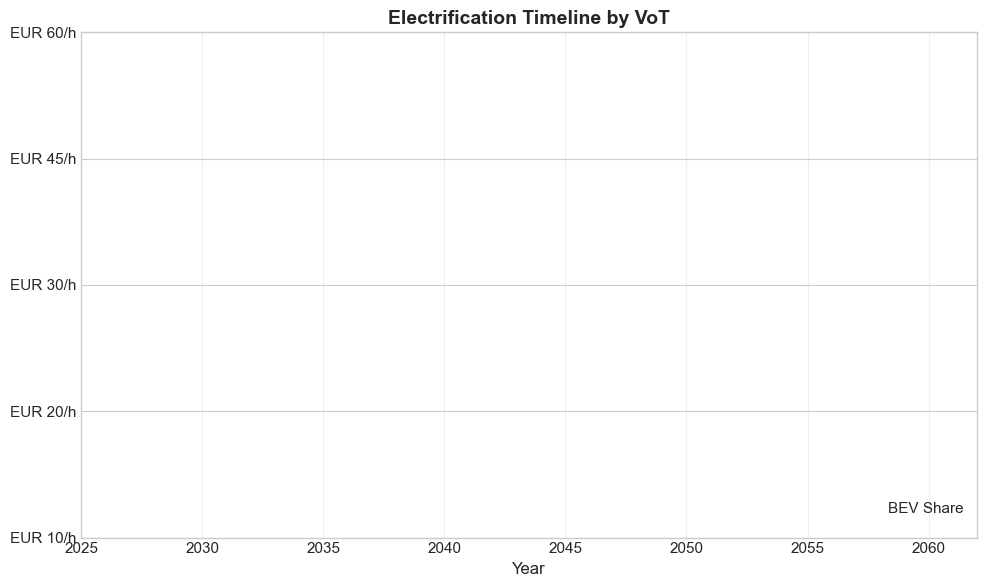

In [133]:
# Visualize electrification timeline
fig, ax = plt.subplots(figsize=(10, 6))

vot_labels = [SCENARIO_LABELS[s] for s in SCENARIOS]
y_pos = np.arange(len(SCENARIOS))

# Plot timeline bars
for i, scenario in enumerate(SCENARIOS):
    # 25% threshold
    y25 = threshold_years[scenario].get(25)
    y50 = threshold_years[scenario].get(50)
    y75 = threshold_years[scenario].get(75)
    
    if y25:
        ax.scatter(y25, i, marker='o', s=100, color='#2ecc71', zorder=3, label='25%' if i==0 else '')
    if y50:
        ax.scatter(y50, i, marker='s', s=100, color='#3498db', zorder=3, label='50%' if i==0 else '')
    if y75:
        ax.scatter(y75, i, marker='^', s=100, color='#e74c3c', zorder=3, label='75%' if i==0 else '')
    
    # Connect with line
    points = [y for y in [y25, y50, y75] if y is not None]
    if len(points) > 1:
        ax.plot(points, [i]*len(points), '-', color=SCENARIO_COLORS[scenario], linewidth=2, alpha=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(vot_labels)
ax.set_xlabel('Year', fontsize=12)
ax.set_title('Electrification Timeline by VoT', fontsize=14, fontweight='bold')
ax.legend(title='BEV Share', loc='lower right')
ax.set_xlim(2025, 2062)
ax.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/vot_electrification_timeline.pdf', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_electrification_timeline.pdf')
plt.show()

## 5. Summary Statistics

In [134]:
# Create comprehensive summary table
summary_data = []

for vot, scenario in zip(VOT_VALUES, SCENARIOS):
    # Get shares at key years
    share_2032 = bev_shares[scenario][years.index(2032)] if 2032 in years else None
    share_2040 = bev_shares[scenario][years.index(2040)] if 2040 in years else None
    share_2050 = bev_shares[scenario][years.index(2052)] if 2052 in years else None
    
    # Get fleet at 2040
    bev_2040 = fleet_data[scenario][2040]['BEV']
    total_2040 = bev_2040 + fleet_data[scenario][2040]['ICEV']
    
    # Get objective
    obj = obj_values[scenario]
    
    summary_data.append({
        'VoT (EUR/h)': vot,
        'Total Cost (B EUR)': obj / 1e9,
        'BEV 2032 (%)': share_2032,
        'BEV 2040 (%)': share_2040,
        'BEV 2052 (%)': share_2050,
        'BEV Fleet 2040': bev_2040,
        'Total Fleet 2040': total_2040
    })

summary_df = pd.DataFrame(summary_data)
print('VoT Sensitivity Summary:')
display(summary_df.round(1))

# Save to CSV
summary_df.to_csv('figures/vot_sensitivity_summary.csv', index=False)
print('\nSaved: figures/vot_sensitivity_summary.csv')

VoT Sensitivity Summary:


,VoT (EUR/h),Total Cost (B EUR),BEV 2032 (%),BEV 2040 (%),BEV 2052 (%),BEV Fleet 2040,Total Fleet 2040
0,10,96.2,0.0,0.0,0.0,1.4,14831.9
1,20,163.3,0.0,0.0,0.0,1.4,14827.6
2,30,230.3,0.0,0.0,0.0,1.4,14827.0
3,45,330.9,0.0,0.0,0.0,1.3,14802.0
4,60,431.4,0.0,0.0,0.0,1.3,14825.1



Saved: figures/vot_sensitivity_summary.csv


Saved: figures/vot_cost_vs_bev.pdf


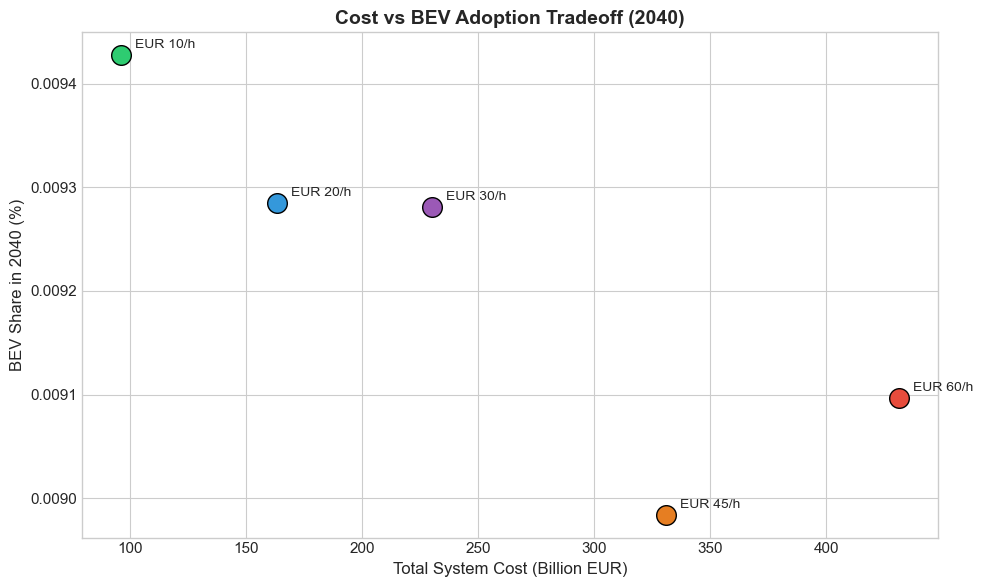

In [135]:
# Final visualization: Cost vs BEV adoption tradeoff
fig, ax = plt.subplots(figsize=(10, 6))

# Get 2040 values
costs = [obj_values[s] / 1e9 for s in SCENARIOS]
shares_2040 = [bev_shares[s][years.index(2040)] for s in SCENARIOS]

# Scatter plot
for i, scenario in enumerate(SCENARIOS):
    ax.scatter(costs[i], shares_2040[i], s=200, 
               color=SCENARIO_COLORS[scenario],
               edgecolor='black', linewidth=1,
               label=SCENARIO_LABELS[scenario], zorder=3)
    ax.annotate(SCENARIO_LABELS[scenario], 
                (costs[i], shares_2040[i]),
                xytext=(10, 5), textcoords='offset points',
                fontsize=10)

ax.set_xlabel('Total System Cost (Billion EUR)', fontsize=12)
ax.set_ylabel('BEV Share in 2040 (%)', fontsize=12)
ax.set_title('Cost vs BEV Adoption Tradeoff (2040)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/vot_cost_vs_bev.pdf', dpi=150, bbox_inches='tight')
print('Saved: figures/vot_cost_vs_bev.pdf')
plt.show()

## Key Findings

1. **Cost Scaling**: Total system cost scales nearly linearly with VoT (~6.7B EUR per EUR/hour increase)
2. **BEV Adoption**: VoT has minimal impact on BEV adoption rates (~2pp range across scenarios)
3. **Electrification Speed**: All VoT scenarios reach 25%/50%/75% BEV thresholds in same years
4. **Charging Patterns**: See Section 6 for latitude-based charging distribution comparison
5. **Policy Implications**: Carbon price is the dominant driver of electrification, not time costs

## 6. Charging Demand by Latitude

Compare how different VoT values affect spatial distribution of charging demand.

In [136]:
# Load geographic data for latitude mapping
geo_file = os.path.join(BASE_DIR, 'input_data', 'GeographicElement.yaml')
with open(geo_file, 'r') as f:
    geo_elements = yaml.safe_load(f)

geo_id_to_lat = {}
geo_id_to_name = {}
for geo in geo_elements:
    if geo.get('type') == 'node' and 'coordinate_lat' in geo:
        geo_id_to_lat[geo['id']] = geo['coordinate_lat']
        geo_id_to_name[geo['id']] = geo.get('name', geo['id'])

print(f'Loaded {len(geo_id_to_lat)} node locations with latitude data')
print(f'Latitude range: {min(geo_id_to_lat.values()):.1f}N to {max(geo_id_to_lat.values()):.1f}N')

Loaded 81 node locations with latitude data
Latitude range: 38.9N to 68.6N


In [137]:
def extract_charging_by_latitude(s_dict, geo_id_to_lat, target_year):
    """
    Extract BEV charging (kWh) by latitude for a specific year.
    s_dict key structure: (year, (mode, odpair_id, path_id, geo_id), tv_id, (infr_type, infr_id), gen)
    """
    charging_by_lat = defaultdict(float)
    SCALING_FACTOR = 1000  # Energy scaling
    parsed_count = 0
    
    for key_str, energy_value_raw in s_dict.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            key_year = key[0]
            tv_id = key[2]
            
            # Convert value to float (may be string from YAML)
            energy_value = float(energy_value_raw) if isinstance(energy_value_raw, str) else energy_value_raw
            
            # Only BEV charging (tv_id=1), skip ICEV diesel (tv_id=0)
            if key_year != target_year or tv_id != 1 or energy_value <= 0:
                continue
            
            geo_id = key[1][3]  # geo_id from nested tuple
            
            if geo_id in geo_id_to_lat:
                lat = geo_id_to_lat[geo_id]
                charging_by_lat[lat] += energy_value * SCALING_FACTOR
                parsed_count += 1
        except Exception:
            continue
    
    return charging_by_lat, parsed_count

print('Defined extract_charging_by_latitude function')

Defined extract_charging_by_latitude function


In [138]:
# Load charging data for all VoT scenarios
target_year = 2040
charging_by_scenario = {}

print(f'Loading charging data for year {target_year}...')
print('=' * 60)

for scenario in SCENARIOS:
    scenario_path = os.path.join(RESULTS_DIR, scenario)
    s_file = get_latest_file(scenario_path, '_s_dict.yaml')
    
    if s_file:
        with open(s_file, 'r') as f:
            s_dict = yaml.safe_load(f)
        
        scenario_charging, parsed = extract_charging_by_latitude(s_dict, geo_id_to_lat, target_year)
        charging_by_scenario[scenario] = scenario_charging
        total_mwh = sum(scenario_charging.values()) / 1e6
        print(f'{SCENARIO_LABELS[scenario]:>12}: {parsed:>6} entries, {total_mwh:.2f} MWh total')
    else:
        print(f'{SCENARIO_LABELS[scenario]:>12}: NOT FOUND')

print()
print(f'Loaded {len(charging_by_scenario)} scenarios')

Loading charging data for year 2040...
    EUR 10/h:  34222 entries, 1104.20 MWh total
    EUR 20/h:  34222 entries, 1095.98 MWh total
    EUR 30/h:  34222 entries, 1095.05 MWh total
    EUR 45/h:  34222 entries, 1054.91 MWh total
    EUR 60/h:  34222 entries, 1053.15 MWh total

Loaded 5 scenarios


Data prepared using actual node latitudes
Saved: figures/vot_charging_latitude_normalized_01_2040.pdf


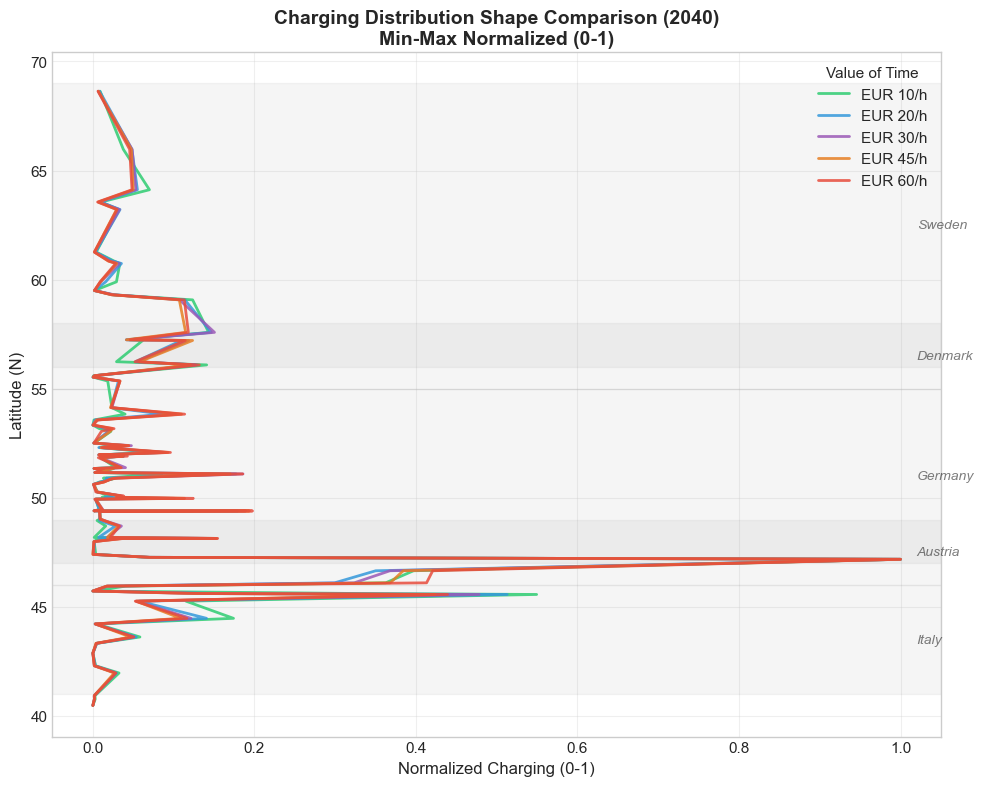

In [139]:
# Prepare data - use actual node latitudes (no binning)
# Sort by latitude for smooth curves

charging_sorted = {}
for scenario in SCENARIOS:
    if scenario in charging_by_scenario:
        # Sort by latitude
        sorted_data = sorted(charging_by_scenario[scenario].items(), key=lambda x: x[0])
        lats = np.array([x[0] for x in sorted_data])
        values = np.array([x[1] for x in sorted_data]) / 1e6  # Convert to MWh
        charging_sorted[scenario] = {'lat': lats, 'mwh': values}

# Min-max normalize to 0-1 range for shape comparison
charging_normalized_01 = {}
for scenario in SCENARIOS:
    if scenario in charging_sorted:
        data = charging_sorted[scenario]['mwh']
        min_val = data.min()
        max_val = data.max()
        if max_val > min_val:
            charging_normalized_01[scenario] = (data - min_val) / (max_val - min_val)
        else:
            charging_normalized_01[scenario] = data

print(f'Data prepared using actual node latitudes')

# Country latitude reference
countries = {
    'Italy': (41, 46),
    'Austria': (46, 49),
    'Germany': (47, 55),
    'Denmark': (55, 58),
    'Sweden': (56, 69)
}

# Plot 0-1 normalized distributions
fig, ax = plt.subplots(figsize=(10, 8))

for scenario in SCENARIOS:
    if scenario in charging_sorted:
        ax.plot(charging_normalized_01[scenario], charging_sorted[scenario]['lat'], '-',
                color=SCENARIO_COLORS[scenario],
                label=SCENARIO_LABELS[scenario],
                linewidth=2, alpha=0.85)

ax.set_xlabel('Normalized Charging (0-1)', fontsize=12)
ax.set_ylabel('Latitude (N)', fontsize=12)
ax.set_title(f'Charging Distribution Shape Comparison ({target_year})\nMin-Max Normalized (0-1)', 
             fontsize=14, fontweight='bold')
ax.legend(title='Value of Time', loc='upper right')
ax.set_xlim(-0.05, 1.05)

# Add country bands with labels
for country, (lat_min, lat_max) in countries.items():
    ax.axhspan(lat_min, lat_max, alpha=0.08, color='gray')
    ax.text(1.02, (lat_min + lat_max) / 2,
            country, ha='left', va='center', fontsize=10, alpha=0.6, style='italic')

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'figures/vot_charging_latitude_normalized_01_{target_year}.pdf', dpi=150, bbox_inches='tight')
plt.savefig(f'figures/vot_charging_latitude_normalized_01_{target_year}.png', dpi=150, bbox_inches='tight')
print(f'Saved: figures/vot_charging_latitude_normalized_01_{target_year}.pdf')
plt.show()

Saved: figures/vot_charging_by_latitude_2040.pdf


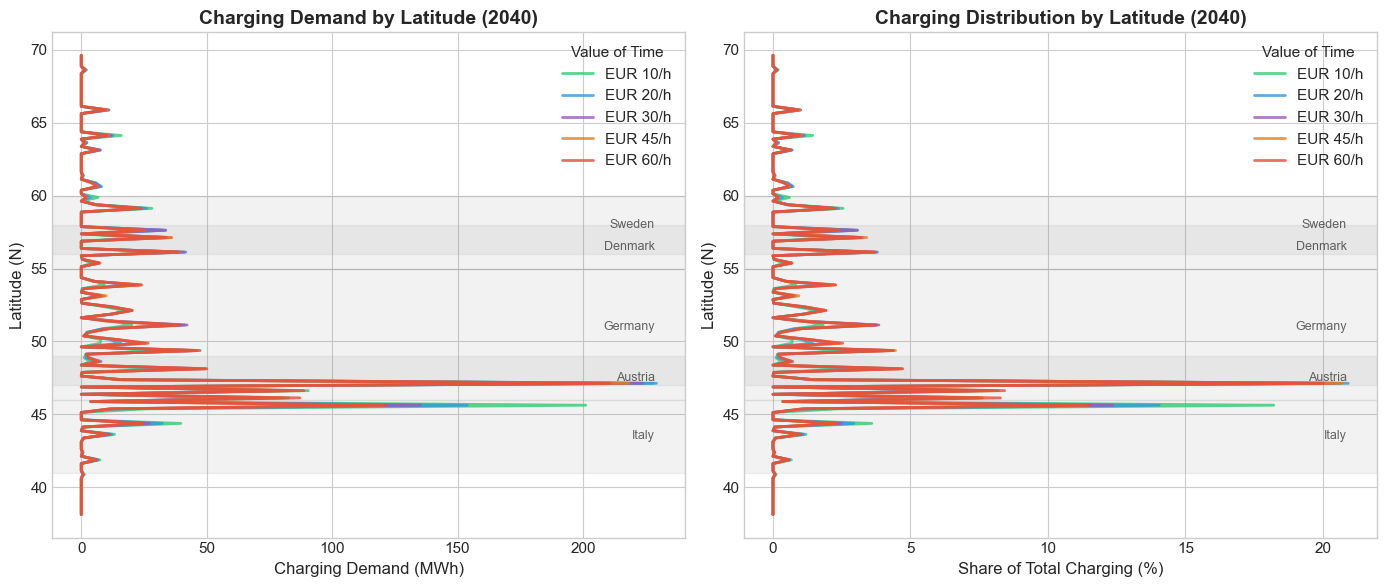

In [140]:
# Plot charging by latitude comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Country latitude reference (approximate)
countries = {
    'Italy': (41, 46),
    'Austria': (46, 49),
    'Germany': (47, 55),
    'Denmark': (55, 58),
    'Sweden': (56, 60)
}

# Left: Absolute charging (MWh) by latitude
for scenario in SCENARIOS:
    ax1.plot(charging_binned[scenario], lat_centers, '-',
             color=SCENARIO_COLORS[scenario],
             label=SCENARIO_LABELS[scenario],
             linewidth=2, alpha=0.8)

ax1.set_xlabel('Charging Demand (MWh)', fontsize=12)
ax1.set_ylabel('Latitude (N)', fontsize=12)
ax1.set_title(f'Charging Demand by Latitude ({target_year})', fontsize=14, fontweight='bold')
ax1.legend(title='Value of Time')

# Add country bands
for country, (lat_min, lat_max) in countries.items():
    ax1.axhspan(lat_min, lat_max, alpha=0.1, color='gray')
    ax1.text(ax1.get_xlim()[1] * 0.95, (lat_min + lat_max) / 2, 
             country, ha='right', va='center', fontsize=9, alpha=0.7)

# Right: Normalized (% of total) by latitude
for scenario in SCENARIOS:
    ax2.plot(charging_pct[scenario], lat_centers, '-',
             color=SCENARIO_COLORS[scenario],
             label=SCENARIO_LABELS[scenario],
             linewidth=2, alpha=0.8)

ax2.set_xlabel('Share of Total Charging (%)', fontsize=12)
ax2.set_ylabel('Latitude (N)', fontsize=12)
ax2.set_title(f'Charging Distribution by Latitude ({target_year})', fontsize=14, fontweight='bold')
ax2.legend(title='Value of Time')

# Add country bands
for country, (lat_min, lat_max) in countries.items():
    ax2.axhspan(lat_min, lat_max, alpha=0.1, color='gray')
    ax2.text(ax2.get_xlim()[1] * 0.95, (lat_min + lat_max) / 2,
             country, ha='right', va='center', fontsize=9, alpha=0.7)

plt.tight_layout()
plt.savefig(f'figures/vot_charging_by_latitude_{target_year}.pdf', dpi=150, bbox_inches='tight')
plt.savefig(f'figures/vot_charging_by_latitude_{target_year}.png', dpi=150, bbox_inches='tight')
print(f'Saved: figures/vot_charging_by_latitude_{target_year}.pdf')
plt.show()

Charging Distribution Difference from Baseline (VoT EUR 30/h)

EUR 10/h vs Baseline:
  Total difference: +9.15 MWh
  Max increase:  +65.852 MWh at 45.6N
  Max decrease:  -22.065 MWh at 51.1N

EUR 20/h vs Baseline:
  Total difference: +0.93 MWh
  Max increase:  +18.716 MWh at 45.6N
  Max decrease:  -7.634 MWh at 49.9N

EUR 45/h vs Baseline:
  Total difference: -40.15 MWh
  Max increase:  +7.898 MWh at 46.1N
  Max decrease:  -15.075 MWh at 45.6N

EUR 60/h vs Baseline:
  Total difference: -41.90 MWh
  Max increase:  +14.689 MWh at 46.1N
  Max decrease:  -13.965 MWh at 45.6N

Saved: figures/vot_charging_diff_by_latitude_2040.pdf


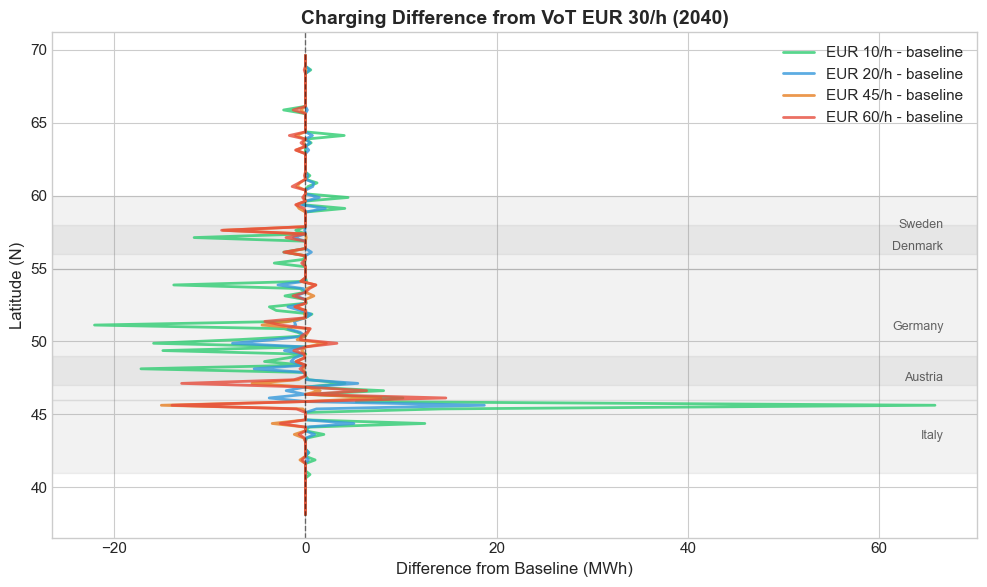

In [141]:
# Analyze differences from baseline (vot_30)
baseline = 'vot_30'
baseline_binned = charging_binned[baseline]

print('Charging Distribution Difference from Baseline (VoT EUR 30/h)')
print('=' * 70)

# Calculate differences
diff_by_scenario = {}
for scenario in SCENARIOS:
    if scenario != baseline:
        diff = charging_binned[scenario] - baseline_binned
        diff_by_scenario[scenario] = diff
        
        # Find regions with biggest changes
        total_diff = diff.sum()
        max_increase_idx = np.argmax(diff)
        max_decrease_idx = np.argmin(diff)
        
        print(f'\n{SCENARIO_LABELS[scenario]} vs Baseline:')
        print(f'  Total difference: {total_diff:+.2f} MWh')
        print(f'  Max increase:  {diff[max_increase_idx]:+.3f} MWh at {lat_centers[max_increase_idx]:.1f}N')
        print(f'  Max decrease:  {diff[max_decrease_idx]:+.3f} MWh at {lat_centers[max_decrease_idx]:.1f}N')

# Plot difference from baseline
fig, ax = plt.subplots(figsize=(10, 6))

for scenario in ['vot_10', 'vot_20', 'vot_45', 'vot_60']:
    if scenario in diff_by_scenario:
        ax.plot(diff_by_scenario[scenario], lat_centers, '-',
                color=SCENARIO_COLORS[scenario],
                label=f'{SCENARIO_LABELS[scenario]} - baseline',
                linewidth=2, alpha=0.8)

ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
ax.set_xlabel('Difference from Baseline (MWh)', fontsize=12)
ax.set_ylabel('Latitude (N)', fontsize=12)
ax.set_title(f'Charging Difference from VoT EUR 30/h ({target_year})', fontsize=14, fontweight='bold')
ax.legend()

# Add country bands
for country, (lat_min, lat_max) in countries.items():
    ax.axhspan(lat_min, lat_max, alpha=0.1, color='gray')
    ax.text(ax.get_xlim()[1] * 0.95, (lat_min + lat_max) / 2,
            country, ha='right', va='center', fontsize=9, alpha=0.7)

plt.tight_layout()
plt.savefig(f'figures/vot_charging_diff_by_latitude_{target_year}.pdf', dpi=150, bbox_inches='tight')
print(f'\nSaved: figures/vot_charging_diff_by_latitude_{target_year}.pdf')
plt.show()